**Checkpoint de 10 posições:** esta análise usa runs/hardpos/checkpoints/gpt_model_HardPos.pt. Na classe de treino, a janela tem 10 PS; entram 9 na rede, e o décimo é o alvo da última previsão.

# Ativação do HardPos × velocidade média do contexto

Cada ponto representa uma janela real de 9 PS de entrada. A velocidade é a média das magnitudes dos 9 vetores de velocidade da janela; o PS seguinte, usado como alvo no treino, fica excluído. Lemos a ativação na última posição de entrada, que pela máscara causal pode incorporar os 99 tokens anteriores.

Amostramos 256 janelas completas por partição da divisão temporal original (treino e validação, aqui também chamada teste). Nenhuma janela cruza a fronteira nem usa padding. As correlações são descritivas: janelas próximas podem se sobrepor, e o modelo não recebe a velocidade diretamente.

In [1]:
%matplotlib inline
from pathlib import Path
import math, pickle
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
from IPython.display import display

root = Path('.')
trainset = pd.read_parquet(root / 'runs/datasets/hardpos/bert_trainset_squared_25.gzip')
with (root / 'runs/datasets/hardpos/ps_to_psid.pkl').open('rb') as f:
    ps_to_psid = pickle.load(f)
ids = trainset['position_state'].map(ps_to_psid)
assert ids.notna().all(), 'PS ausente no mapeamento do treino'
ids = ids.to_numpy(np.int64)
velocity = np.stack(trainset['vel'].to_numpy()).astype(float)
speed = np.linalg.norm(velocity, axis=1)
assert np.isfinite(speed).all()
max_len = 10
context_len = max_len - 1
split_index = int(.8 * len(ids))
pad_token_id = int(ids.max()) + 1
vocab_size = pad_token_id + 1
print(f'{len(ids)} registros; fronteira temporal {split_index}; contexto de {context_len} PS')
from project_support.csv_runs import notebook_csv_path


13134 registros; fronteira temporal 10507; contexto de 9 PS


In [2]:
# Mesmos limites da classe TrajectoryARDataset_FixLen: a janela tem 10 PS,
# sendo 9 entradas e o décimo o alvo seguinte.
train_starts = np.arange(0, split_index - max_len + 1)
test_starts = np.arange(split_index, len(ids) - max_len + 1)
rng = np.random.default_rng(42)
n_per_split = 256
assert min(len(train_starts), len(test_starts)) >= n_per_split
starts_train = np.sort(rng.choice(train_starts, n_per_split, replace=False))
starts_test = np.sort(rng.choice(test_starts, n_per_split, replace=False))
starts = np.concatenate([starts_train, starts_test])
splits = np.array(['treino'] * n_per_split + ['teste'] * n_per_split)
window_index = starts[:, None] + np.arange(context_len)[None, :]
contexts = ids[window_index]
context_speed = speed[window_index].mean(axis=1)
target_ids = ids[starts + context_len]
assert (starts_train + max_len - 1 < split_index).all()
assert (starts_test >= split_index).all()
assert (contexts != pad_token_id).all()
assert np.allclose(context_speed, np.array([speed[s:s+context_len].mean() for s in starts]))
meta = pd.DataFrame({
    'split': splits, 'start_index': starts, 'context_len': context_len,
    'mean_context_speed': context_speed, 'last_input_ps_id': contexts[:, -1],
    'target_ps_id': target_ids,
})
display(meta.groupby('split')['mean_context_speed'].agg(['count','mean','std','min','max']))
display(meta.head(3))

,count,mean,std,min,max
split,,,,,
teste,256,0.126989,0.037583,0.055339,0.267831
treino,256,0.125160,0.035654,0.059166,0.221685


,split,start_index,context_len,mean_context_speed,last_input_ps_id,target_ps_id
0,treino,76,9,0.189292,264,261
1,treino,200,9,0.077250,197,199
2,treino,234,9,0.186937,358,359


In [3]:
# Carrega as classes já definidas no notebook de treinamento sem executar o treino.
import json
training_nb = json.loads((root / 'navitran_vizz_reboot_gpt_squared_25_span.ipynb').read_text(encoding='utf-8'))
for cell_no in (21, 23):
    exec(''.join(training_nb['cells'][cell_no]['source']), globals())
model = TrajectoryBERT_HardPos(
    vocab_size, embed_size=16, num_layers=1, num_heads=1, hidden_dim=32,
    dropout=.2, pad_token_id=pad_token_id, max_len=max_len, causal=True,
)
model.load_state_dict(torch.load(root / 'runs/hardpos/checkpoints/gpt_model_HardPos.pt', map_location='cpu', weights_only=True))
model.eval()
torch.set_num_threads(min(4, torch.get_num_threads()))
layer = model.encoder.layers[0]

@torch.inference_mode()
def extract_last_position(batch):
    token = model.embedding(batch)
    pos = model.position_embedding(token)
    q, k, v = F.linear(pos, layer.self_attn.in_proj_weight,
                       layer.self_attn.in_proj_bias).chunk(3, dim=-1)
    mask = model._causal_mask(batch.shape[1], batch.device)
    attn, _ = layer.self_attn(pos, pos, pos, attn_mask=mask, need_weights=False)
    residual1 = pos + layer.dropout1(attn)
    norm1 = layer.norm1(residual1)
    ff_linear1 = layer.linear1(norm1)
    ff_activation = layer.activation(ff_linear1)
    ff_linear2 = layer.linear2(layer.dropout(ff_activation))
    residual2 = norm1 + layer.dropout2(ff_linear2)
    norm2 = layer.norm2(residual2)
    reps = {
        'token_embedding': token, 'embedding_plus_position': pos,
        'query_projection': q, 'key_projection': k, 'value_projection': v,
        'attention_output': attn, 'attention_residual': residual1,
        'attention_norm': norm1, 'ff_linear1': ff_linear1,
        'ff_activation': ff_activation, 'ff_linear2': ff_linear2,
        'ff_residual': residual2, 'encoder_output': norm2,
    }
    return {name: values[:, -1, :].cpu().numpy() for name, values in reps.items()}, norm2

all_reps = {}
for offset in range(0, len(contexts), 32):
    batch = torch.from_numpy(contexts[offset:offset+32])
    reps, encoder_sequence = extract_last_position(batch)
    if offset == 0:
        with torch.inference_mode():
            direct = model(batch)[:, -1, :]
            manual = model.fc_out(encoder_sequence[:, -1, :])
        torch.testing.assert_close(manual, direct, atol=1e-5, rtol=1e-5)
    for name, values in reps.items():
        all_reps.setdefault(name, []).append(values)
features = {}
for name, blocks in all_reps.items():
    matrix = np.concatenate(blocks, axis=0)
    for d in range(matrix.shape[1]):
        features[f'{name}__d{d:02d}'] = matrix[:, d]
activation = pd.concat([meta, pd.DataFrame(features)], axis=1)
activation.to_parquet(root / 'runs/hardpos/analysis/HardPos_contexto_contexto10_ativacao_velocidade.parquet', index=False)
feature_columns = list(features)
print(f'{len(activation)} janelas, {len(feature_columns)} dimensões salvas')

512 janelas, 240 dimensões salvas


/home/mgteus/workspace/navitrans/.nav/lib/python3.10/site-packages/torch/nn/modules/transformer.py:307: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.num_heads is odd
  warnings.warn(f"enable_nested_tensor is True, but self.use_nested_tensor is False because {why_not_sparsity_fast_path}")


## Relação com a velocidade média

O mapa mostra Spearman de cada dimensão com a velocidade média do contexto, separando treino e teste. A seleção dos exemplos abaixo usa exclusivamente o treino; assim podemos observar se as mesmas dimensões mantêm a relação no trecho temporal reservado.

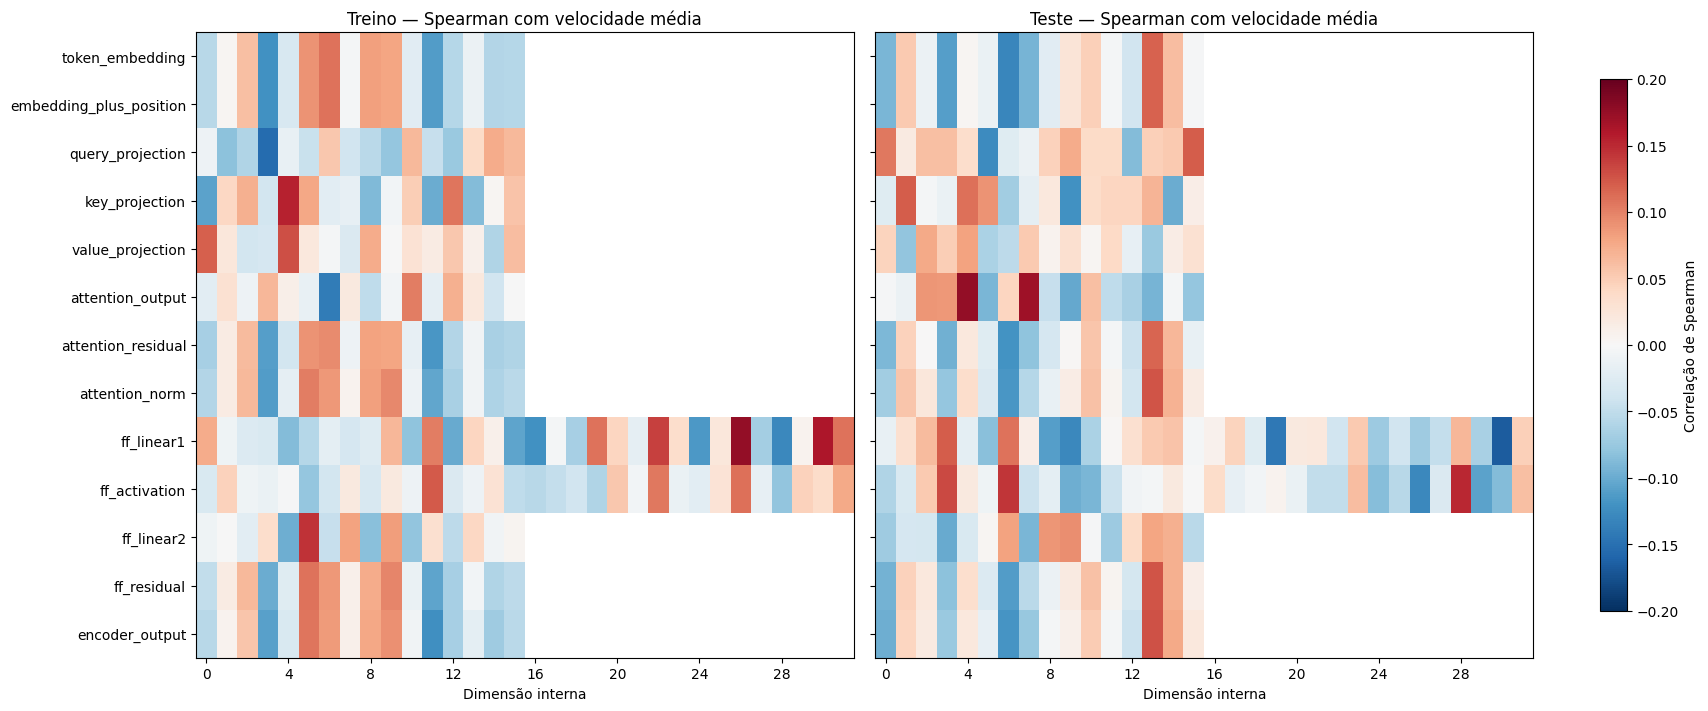

split,teste,treino
feature,,
ff_linear1__d26,-0.070,0.176
query_projection__d03,0.060,-0.154
key_projection__d04,0.110,0.153
ff_linear2__d05,0.003,0.145
attention_output__d06,0.043,-0.139
value_projection__d04,0.081,0.128


In [4]:
rows = []
for feature in feature_columns:
    name, d = feature.rsplit('__d', 1)
    for split in ('treino', 'teste'):
        part = activation.loc[activation['split'] == split]
        a = part[feature].to_numpy(float)
        s = part['mean_context_speed'].to_numpy(float)
        rho = float(spearmanr(a, s).statistic) if np.std(a) > 1e-12 else np.nan
        pearson = float(np.corrcoef(a, s)[0, 1]) if np.std(a) > 1e-12 else np.nan
        rows.append((feature, name, int(d), split, rho, pearson))
corr = pd.DataFrame(rows, columns=['feature','representation','dimension','split','spearman','pearson'])
corr.to_csv(notebook_csv_path('HardPos_contexto_vs_velocidade_contexto10', 'HardPos_contexto_contexto10_velocidade_correlacoes.csv'), index=False)
representations = list(dict.fromkeys(corr['representation']))
fig, axes = plt.subplots(1, 2, figsize=(17, 7), sharey=True, constrained_layout=True)
limit = max(.2, float(np.nanmax(np.abs(corr['spearman']))))
for ax, split in zip(axes, ('treino', 'teste')):
    subset = corr[corr['split'] == split]
    matrix = np.full((len(representations), 32), np.nan)
    for row in subset.itertuples():
        matrix[representations.index(row.representation), row.dimension] = row.spearman
    im = ax.imshow(matrix, aspect='auto', cmap='RdBu_r', vmin=-limit, vmax=limit)
    ax.set_title(f'{split.capitalize()} — Spearman com velocidade média')
    ax.set_xlabel('Dimensão interna')
    ax.set_xticks(np.arange(0, 32, 4))
    ax.set_yticks(range(len(representations)), representations)
fig.colorbar(im, ax=axes, label='Correlação de Spearman', shrink=.85)
(root / 'imgs').mkdir(exist_ok=True)
fig.savefig(root / 'imgs/hardpos_contexto_contexto10_velocidade_mapa.png', dpi=160, bbox_inches='tight')
display(fig)
plt.close(fig)

train_corr = corr[corr['split'] == 'treino'].dropna(subset=['spearman']).copy()
train_corr['abs_rho'] = train_corr['spearman'].abs()
selected = train_corr.sort_values('abs_rho', ascending=False).drop_duplicates('representation').head(6)['feature'].tolist()
summary = corr[corr['feature'].isin(selected)].pivot(index='feature', columns='split', values='spearman')
display(summary.sort_values('treino', key=lambda s: s.abs(), ascending=False).round(3))

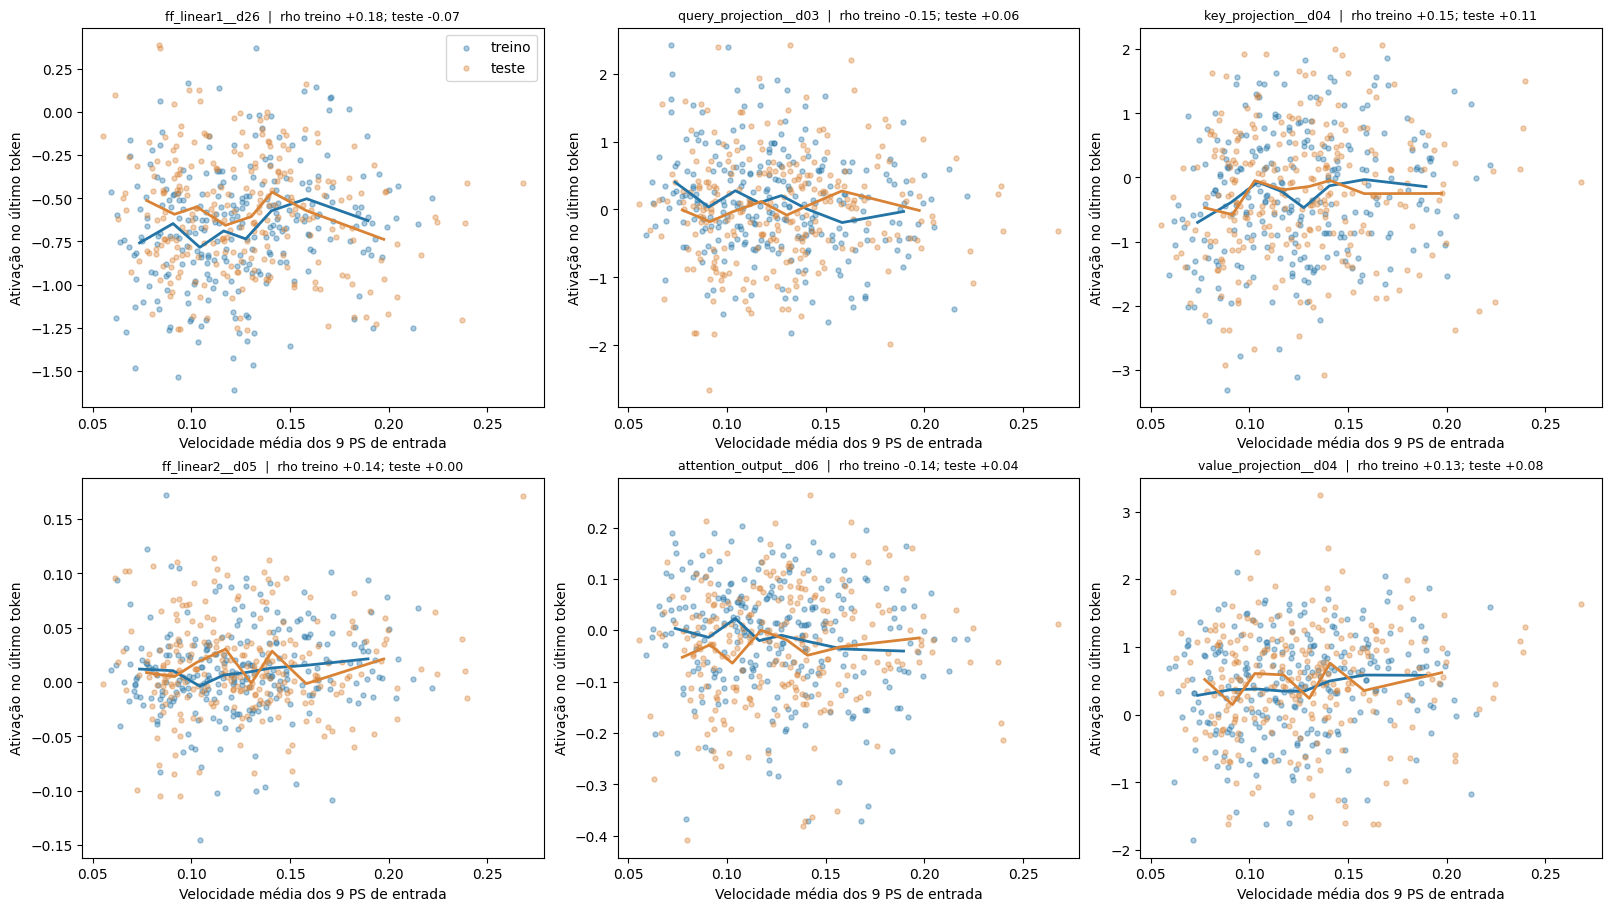

Maior |rho| no treino: 0.176
Maior |rho| no teste: 0.175


In [5]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9), constrained_layout=True)
for ax, feature in zip(axes.flat, selected):
    for split, color in [('treino', '#2474a6'), ('teste', '#d98337')]:
        part = activation[activation['split'] == split]
        ax.scatter(part['mean_context_speed'], part[feature], s=13,
                   color=color, alpha=.38, label=split)
        x = part['mean_context_speed'].to_numpy(float)
        y = part[feature].to_numpy(float)
        edges = np.quantile(x, np.linspace(0, 1, 9))
        mids, means = [], []
        for left, right in zip(edges[:-1], edges[1:]):
            keep = (x >= left) & (x <= right if right == edges[-1] else x < right)
            if keep.any():
                mids.append(x[keep].mean())
                means.append(y[keep].mean())
        ax.plot(mids, means, color=color, lw=2)
    a = summary.loc[feature]
    ax.set_title(f'{feature}  |  rho treino {a["treino"]:+.2f}; teste {a["teste"]:+.2f}', fontsize=9)
    ax.set_xlabel('Velocidade média dos 9 PS de entrada')
    ax.set_ylabel('Ativação no último token')
axes.flat[0].legend()
fig.savefig(root / 'imgs/hardpos_contexto_contexto10_velocidade_exemplos.png', dpi=160, bbox_inches='tight')
display(fig)
plt.close(fig)
print('Maior |rho| no treino:', round(train_corr['abs_rho'].max(), 3))
print('Maior |rho| no teste:', round(corr.loc[corr['split'] == 'teste', 'spearman'].abs().max(), 3))